<center>МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ </center>
<center>ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ ВЫСШЕГО ОБРАЗОВАНИЯ </center>
<center>«НОВОСИБИРСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНИЧЕСКИЙ УНИВЕРСИТЕТ»</center>
<center>Кафедра Вычислительной техники </center>
<br>
<center> <b> <font size="5">  ОТЧЁТ </font>  </b>  </center>   
<center><font size="3">по лабораторной работе №1</font></center>
<center><font size="3">по дисциплине: «Системы искусственного интеллекта и машинное обучение» </font></center>
<br>

Выполнили студенты гр. АВТ-342:
- Звизжева Н.С.
- Звизжева Н.С.

Проверил: Осипенко И.В.

<center>  Новосибирск, 2026  </center>


# Лабораторная работа #1

## Цель работы

Получить практические навыки работы по решению задачи первичного анализа «сырых» данных, подготовки массива к обработке, выявлению и описанию зависимостей в исходных данных с использованием языка программирования Python.

## Ход работы

Ход работы:
- - - - - - - - -

1. Первичный анализ
2. Выбор и обработка признаков
3. Построение линейных регрессионных моделей для каждой выбранной комбинации признаков
4. Выполнение анализа полученных моделей:
5. Оценка в минутах времени, затраченного на выполнение основных этапов текущей работы, согласно методологии CRISP.


# Работа с данными

In [1]:
# Проверка версии и пути к выбранному интерпретатору
import sys
print(f"Версия Python - {sys.version}")
print(f"Путь к интерпретатору Python - {sys.executable}")

Версия Python - 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Путь к интерпретатору Python - C:\Python313\python.exe


In [2]:
# Python 3.13
import pandas as pd
import numpy  as np

import sklearn
from sklearn import linear_model
from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score

%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import cm
import seaborn as sns

In [3]:
# Проверка версий библиотек
for lib in [pd, np, sklearn]:
    print(f"{lib.__name__:<12} {lib.__version__}")

pandas       3.0.6
numpy        2.5.3
sklearn      1.9.1


## Загрузка входных данных

Данные "Diamonds_price" содержат информацию о характеристиках и ценах бриллиантов.

In [4]:
df = pd.read_csv(
    'data/diamonds_nan_24.csv', # путь к файлу через символ "/", (используйте автодополнение)
    sep       = '\t' ,
    decimal   = ',' ,
    header    = 0,  
    na_values =  ['???', 'isntKnown'],
)

df[0:2] # отобразить первые строки таблицы df

,ID,carat,cut,color,clarity,depth,table,price,x,y,z
0,1.0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,2.0,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31


Переменная __df__ является экземпляром класса __DataFrame__ библиотеки __pandas__.

"DataFrame" - двумерный массив с изменяемым размером  набором полезных функций, каждый столбец которого является экземпляром класса "Series".

Осмотрим полученную таблицу и убедимся, что данные загружены и  корректно разделены на ячейки.

In [5]:
df [0:3]

,ID,carat,cut,color,clarity,depth,table,price,x,y,z
0,1.0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,2.0,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,3.0,0.23,Good,E,VS1,56.9,65.0,NaN,4.05,4.07,2.31


## Осмотр данных / Первичный анализ

### Размер таблицы

In [6]:
print  (df.shape)
nrow = df.shape[0]
ncol = df.shape[1]
print ("Итого: " + str(nrow) + " записи, " + str(ncol) + " столбец (признак).")

(53940, 11)
Итого: 53940 записи, 11 столбец (признак).


### Проверка соответствия типов данных для признаков.

После загрузки файла необходимо проверить, что типы данных каждого столбца (или хотя бы основных) советуют нашим ожиданиям.
При чтении файла с использованием библиотеки pandas, если в столбце встречается хотя бы одно значение в виде символа или строки, то все значения в столбце будут интерпретированы как строковые. Часто при заполении таблиц, в ячейку с отсутствующим значением вносят специальную запись-индикатор. В нашем случае, в массиве используется запись `"isntKnown"`. Укажем в параметре при чтении файла.

In [68]:
df.info()

<class 'pandas.DataFrame'>
Index: 53711 entries, 0 to 53939
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   carat          53711 non-null  float64
 1   cut            53711 non-null  str    
 2   color          53711 non-null  str    
 3   clarity        53711 non-null  str    
 4   depth          53711 non-null  float64
 5   table          53711 non-null  float64
 6   price          53711 non-null  float64
 7   x              53711 non-null  float64
 8   y              53711 non-null  float64
 9   z              53711 non-null  float64
 10  clarity_digit  53711 non-null  int64  
 11  cut_digit      53711 non-null  int64  
 12  color_digit    53711 non-null  int64  
dtypes: float64(7), int64(3), str(3)
memory usage: 6.3 MB


In [8]:
df[:3]

,ID,carat,cut,color,clarity,depth,table,price,x,y,z
0,1.0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,2.0,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,3.0,0.23,Good,E,VS1,56.9,65.0,NaN,4.05,4.07,2.31


### Статистические характеристики признаков

In [9]:
# описание для числовых значений. Оператор ".T" транспонирует матрицу для удобства чтения
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,53918.0,26969.156775,15571.226610,1.0,13483.25,26969.50,40454.75,53940.00
carat,53918.0,0.797964,0.474026,0.2,0.40,0.70,1.04,5.01
depth,53918.0,61.749662,1.432544,43.0,61.00,61.80,62.50,79.00
table,53909.0,57.457564,2.234701,43.0,56.00,57.00,59.00,95.00
price,53916.0,3933.043048,3989.504432,326.0,950.00,2401.00,5324.25,18823.00
x,53924.0,5.731093,1.121738,0.0,4.71,5.70,6.54,10.74
y,53914.0,5.734673,1.142057,0.0,4.72,5.71,6.54,58.90
z,53918.0,3.538762,0.705747,0.0,2.91,3.53,4.04,31.80


Также, в таблице содержатся столбцы со строковыми типами данных. Выведем информацию о них:

In [10]:
# описание для НЕ числовых значений, при их наличии
if (df.dtypes == 'str').sum() >0:
    print(df.describe(include=['str', 'bool']).T )

         count unique    top   freq
cut      53917      5  Ideal  21544
color    53919      7      G  11288
clarity  53918      8    SI1  13059


## Удаление признаков (столбцов)

Внимательно осмотрев вывод `df.describe` вышестоящей ячейки и столбце "unique", составим список признаков для удаления: ID

In [11]:
# Удалить столбцы из таблицы можно только один раз
df = df.drop (
    labels = ['ID'], # список названий столбцов
    axis=1 # удаление строк
    )
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='str')

In [12]:
print ("Итого: " + str(df.shape[0]) + " записи, " + str(df.shape[1]) + " столбец (признак).")

Итого: 53940 записи, 10 столбец (признак).


## Пропущенные значения

Осмотрим значения последних пяти объектов, обратим внимание на значения __NaN__ - особые значение для заполнения отсутствующих в источнике.

In [13]:
df[:3]

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,NaN,4.05,4.07,2.31


Сформируем __таблицу-маску__ для обнаружения отсутствующих значений.

In [14]:
df.isna()[:3]

,carat,cut,color,clarity,depth,table,price,x,y,z
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,True,False,False,False


Над таблицей __таблицей-маской__ допустимо выполнить агрегирующую функцию __.sum()__  и т.к. наша таблица состоит из столбцов Series, то будет получена сумма по столбцам, при этом каждое значение TRUE будет приведено к единице. В результате мы получим количество пропущенных элементов по каждому признаку.

In [15]:
print ( df.isna().sum() ) # используем print для компактного вывода

carat      22
cut        23
color      21
clarity    22
depth      22
table      31
price      24
x          16
y          26
z          22
dtype: int64


Для понимания как распределены отсутствующие значения в исходной таблице, попробуем получить графическое изображение __таблицы-маски__

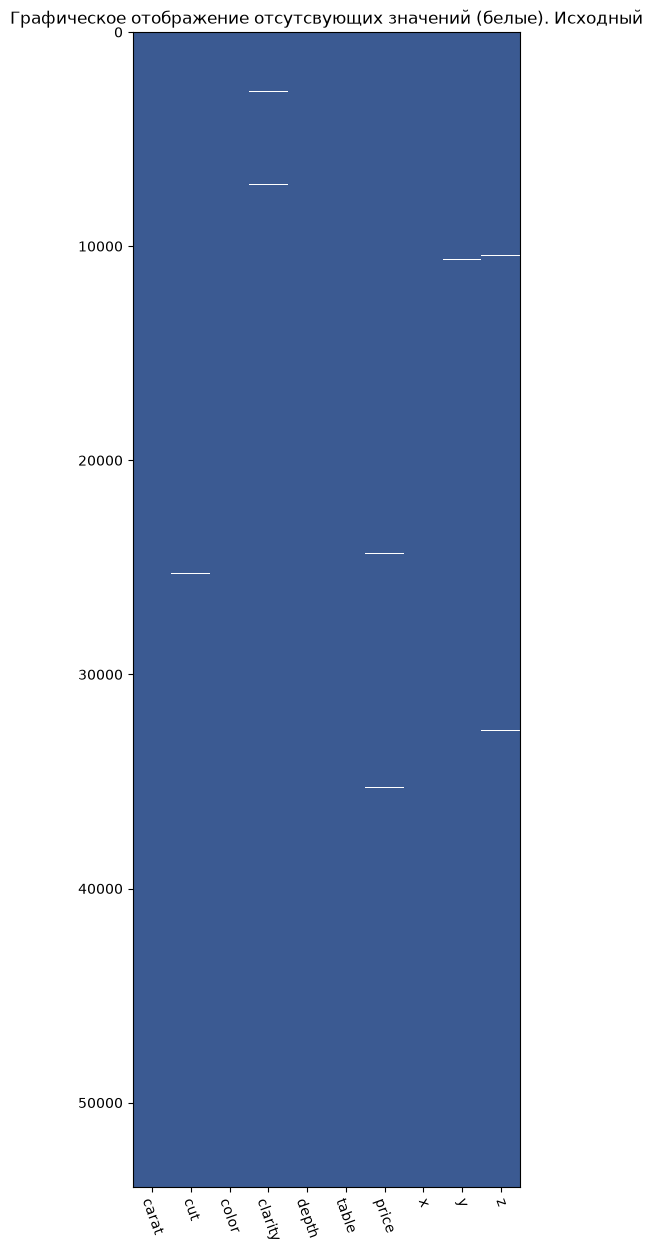

In [16]:
from matplotlib.colors import ListedColormap
def plotTableNA(dataF, addToTilte =""):
    '''  Функция для построения графика отображение отсутсвующих значений'''
    if   len(dataF.columns)> 20:   K = 3
    elif len(dataF.columns)== 1:   K = 1
    else:                          K = 1.7

    figSizeH = 15        # размер полотна, высота
    figSizeW =int(len(dataF.columns)/K) # размер полотна, ширина
    fig, ax = plt.subplots( figsize=(figSizeW, figSizeH)) # создать полотно для рисования, figsize-размер в дюймах

    # отрисовать матрицу значений функцией imshow. Применяется цветовая палитра
    plt.imshow( dataF.isna(),
                cmap = ListedColormap([ '#3B5A92', 'white', ]), # выбор цветовой шкалы, аналог cm.get_cmap('jet'),
                aspect='auto',  # ‘auto’ | ‘equal’ | scalar]    # режим соотнощения сторон
                interpolation= 'none',)                         # отключить размытие
    ax.set_xticks(np.arange(len(dataF.columns)))
    ax.set_xticklabels(dataF.columns, rotation=-70,)
    plt.title("Графическое отображение отсутсвующих значений (белые). "+ addToTilte)
    plt.grid(False) # Сетка
#-------------------------------------
# Вызов функции с указанием параметров
plotTableNA( dataF=df, addToTilte="Исходный" )

Отсутвующие значения будут препятсвовать дальнейшим расчётам и анализу данных.

In [17]:
print("Размер исходного DataFrame", df.shape)
print("Вар.2.1. Размер при исключении по строкам",  df.dropna(axis='index', how='any').shape)
print("Вар.2.2. Размер при исключении по столбцам", df.dropna(axis='columns', how='any').shape)

Размер исходного DataFrame (53940, 10)
Вар.2.1. Размер при исключении по строкам (53711, 10)
Вар.2.2. Размер при исключении по столбцам (53940, 0)


Пропущенные значения присутствуют лишь в небольшой части записей. Все признаки датасета предположительно информативны (масса, характеристики качества и размеры камня), поэтому удалять столбцы нецелесообразно. При удалении строк с пропусками теряется менее 1% данных, что не повлияет на результаты анализа при объёме выборки более 53 тыс. записей. Заполнение пропусков вычисленными значениями не применялось, чтобы не вносить в данные искусственные значения, особенно в целевую переменную price.

In [18]:
# axis='index'   - режим удаление строк, в которых есть пропуски
# axis='columns' - режим удаление столбцов, в которых есть пропуски
df = df.dropna(axis='index', how='any')
print("Размер таблицы после исключения пропусков", df.shape)

Размер таблицы после исключения пропусков (53711, 10)


Необходимо убедится в том, что ожидаемый результат совпадает с фактическим.

In [19]:
print (df.isna().sum()) # используем print для компактного вывода

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


In [20]:
print ("Итого: " + str(df.shape[0]) + " записи, " + str(df.shape[1]) + " столбец (признак).")

Итого: 53711 записи, 10 столбец (признак).


## Преобразование к числовым типам категориальных признаков и даты/времени

На текущем этапе в таблице присутствуют не числовые столбцы (тип данных object): Для дальнейшего анализа, их необходимо преобразовать к числовым значениям (тип данных int, float) определёнными способами.

In [21]:
df.info()

<class 'pandas.DataFrame'>
Index: 53711 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53711 non-null  float64
 1   cut      53711 non-null  str    
 2   color    53711 non-null  str    
 3   clarity  53711 non-null  str    
 4   depth    53711 non-null  float64
 5   table    53711 non-null  float64
 6   price    53711 non-null  float64
 7   x        53711 non-null  float64
 8   y        53711 non-null  float64
 9   z        53711 non-null  float64
dtypes: float64(7), str(3)
memory usage: 5.1 MB


В нашем случае категориальными признаками являются цвет, огранка и чистота.

In [22]:
df.describe(include=['str', 'bool']).T  # описание для не числовых значений

,count,unique,top,freq
cut,53711,5,Ideal,21466
color,53711,7,G,11247
clarity,53711,8,SI1,13012


### Замена значений (mapping)

У нас три строковых признака и все они дискретные категориальные. У каждого из них ограниченный набор значений, и все значения можно расставить по шкале качества. Поэтому для всех трёх подходит map.
Используем функцию `.map`, в качестве параметра передадим словарь соответствий (пары ключ=значение).

Каждой категории присваивается целое число так, что большее число соответствует лучшему качеству. Это сохраняет информацию о порядке градаций, и линейная модель может её учесть.

Первым шагом, получим в виде списка все уникальные значения выбранного признака.

In [23]:
df['clarity'].unique()

<ArrowStringArray>
['SI2', 'SI1', 'VS2', 'VVS2', 'VVS1', 'VS1', 'I1', 'IF']
Length: 8, dtype: str

Признак clarity принимает 8 значений. Чистота характеризует количество и заметность внутренних включений в камне. Согласно общепринятой классификации, градации объеденим в 5 категорий.

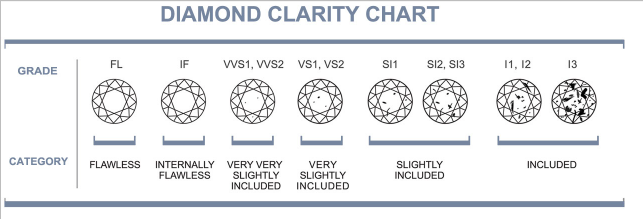

In [24]:
df['clarity_digit'] = df['clarity'].map(
  {
    'I1' : 1,
    'SI1' : 2,
    'SI2' : 2,
    'VS1' : 3,
    'VS2' : 3,
    'VVS1' : 4,
    'VVS2' : 4,
    'IF' : 5,
  }
)
df[[ 'clarity' , 'clarity_digit']] [:2]

,clarity,clarity_digit
0,SI2,2
1,SI1,2


In [25]:
df['cut'].unique()

<ArrowStringArray>
['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Length: 5, dtype: str

Признак cut принимает 5 значений. Качество огранки определяет, насколько хорошо камень отражает свет. Значения закодированы по возрастанию качества.

In [26]:
df['cut_digit'] = df['cut'].map(
  {
    'Ideal' : 5,
    'Premium' : 4,
    'Very Good' : 3,
    'Good' : 2,
    'Fair' : 1,
  }
)
df[[ 'cut' , 'cut_digit']] [:2]

,cut,cut_digit
0,Ideal,5
1,Premium,4


In [27]:
df["color"].nunique() # получить количество уникальных значений в столбце

7

In [28]:
df['color'].unique() # получить массив уникальных значений в столбце

<ArrowStringArray>
['E', 'I', 'J', 'H', 'F', 'G', 'D']
Length: 7, dtype: str

Признак color принимает 7 значений. Значения закодированы по возрастанию качества.

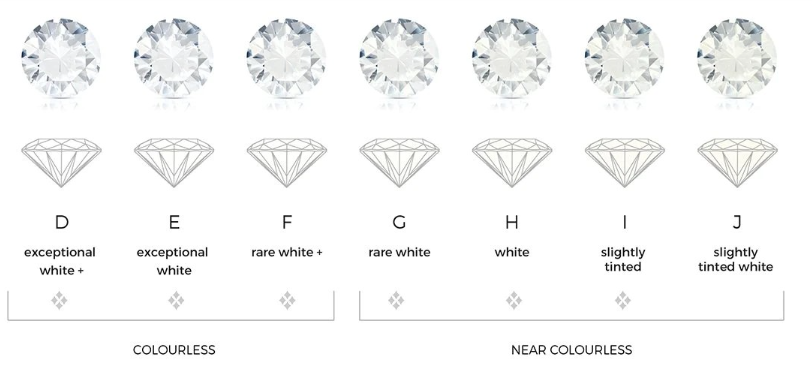

In [29]:
df['color_digit'] = df['color'].map(
  {
    'J' : 1,
    'I' : 2,
    'H' : 3,
    'G' : 4,
    'F' : 5,
    'E' : 6,
    'D' : 7,
  }
)
df[[ 'color' , 'color_digit']] [:2]

,color,color_digit
0,E,6
1,E,6


In [30]:
df.info()

<class 'pandas.DataFrame'>
Index: 53711 entries, 0 to 53939
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   carat          53711 non-null  float64
 1   cut            53711 non-null  str    
 2   color          53711 non-null  str    
 3   clarity        53711 non-null  str    
 4   depth          53711 non-null  float64
 5   table          53711 non-null  float64
 6   price          53711 non-null  float64
 7   x              53711 non-null  float64
 8   y              53711 non-null  float64
 9   z              53711 non-null  float64
 10  clarity_digit  53711 non-null  int64  
 11  cut_digit      53711 non-null  int64  
 12  color_digit    53711 non-null  int64  
dtypes: float64(7), int64(3), str(3)
memory usage: 6.3 MB


### 

## Формирование таблицы с строго числовыми значениями

Для выполнения следующих частей работы необходимо выбрать только те столбцы, которые представлены в числовом типе данных.


Выберем из исходной таблицы нужные столбцы по их названиям и сохраним результат в новую таблицу `df_digital`.

In [31]:
# список названий числовых признаков исходной таблицы
digitColName = [
    'carat'       ,
    'depth'       ,
    'table'    ,
    'price'    ,
    'x'    ,
    'y'    ,
    'z'         ,
    'color_digit'    ,
    'cut_digit'   ,
    'clarity_digit'   ,
                    ]

df_digPlus = df [digitColName]
df_digPlus

,carat,depth,table,price,x,y,z,color_digit,cut_digit,clarity_digit
0,0.23,61.5,55.0,326.0,3.95,3.98,2.43,6,5,2
1,0.21,59.8,61.0,326.0,3.89,3.84,2.31,6,4,2
3,0.29,62.4,58.0,334.0,4.20,4.23,2.63,2,4,3
4,0.31,63.3,58.0,335.0,4.34,4.35,2.75,1,2,2
5,0.24,62.8,57.0,336.0,3.94,3.96,2.48,1,3,4
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,60.8,57.0,2757.0,5.75,5.76,3.50,7,5,2
53936,0.72,63.1,55.0,2757.0,5.69,5.75,3.61,7,2,2
53937,0.70,62.8,60.0,2757.0,5.66,5.68,3.56,7,3,2
53938,0.86,61.0,58.0,2757.0,6.15,6.12,3.74,3,4,2


# Выбор целевого значения и признаков для анализа данных

## Корреляция

Построим матрицу корреляции - матрицу значений коэфф. корреляции Пирсона для возможных комбинаций пар.

In [32]:
corr_df = df_digPlus.corr(method='pearson')
corr_df

,carat,depth,table,price,x,y,z,color_digit,cut_digit,clarity_digit
carat,1.000000,0.028318,0.182417,0.921513,0.975088,0.951616,0.953282,-0.291540,-0.135428,-0.329099
depth,0.028318,1.000000,-0.295878,-0.010793,-0.025175,-0.029253,0.095057,-0.046949,-0.218507,-0.072876
table,0.182417,-0.295878,1.000000,0.127774,0.196208,0.184579,0.151726,-0.026896,-0.433190,-0.156409
price,0.921513,-0.010793,0.127774,1.000000,0.884396,0.865296,0.861090,-0.172434,-0.053748,-0.128659
x,0.975088,-0.025175,0.196208,0.884396,1.000000,0.974595,0.970675,-0.270335,-0.126111,-0.349124
y,0.951616,-0.029253,0.184579,0.865296,0.974595,1.000000,0.951827,-0.263599,-0.121968,-0.336164
z,0.953282,0.095057,0.151726,0.861090,0.970675,0.951827,1.000000,-0.268213,-0.149915,-0.345594
color_digit,-0.291540,-0.046949,-0.026896,-0.172434,-0.270335,-0.263599,-0.268213,1.000000,0.020438,-0.012304
cut_digit,-0.135428,-0.218507,-0.433190,-0.053748,-0.126111,-0.121968,-0.149915,0.020438,1.000000,0.191237
clarity_digit,-0.329099,-0.072876,-0.156409,-0.128659,-0.349124,-0.336164,-0.345594,-0.012304,0.191237,1.000000


Для того, чтобы визуально оценить величину коэффициентов корреляции, построим тепловую карту по значениям взаимозависимости признаков выборки.

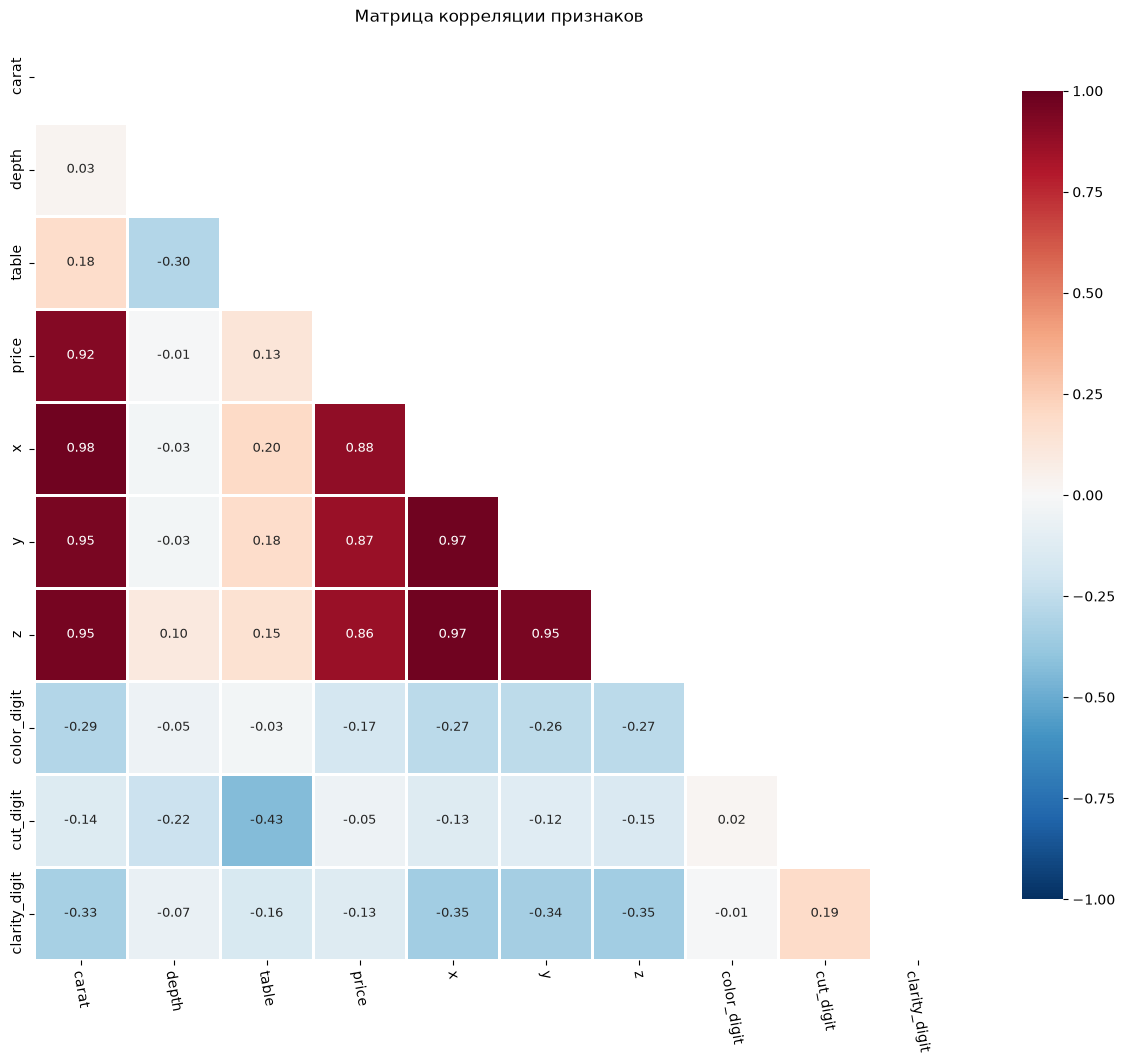

In [33]:
# построить "маску" для отображения только половины корреляционной матрицы
mask = np.zeros_like(corr_df, dtype=np.bool_)
mask[np.triu_indices_from(mask)] = True

# Построить тепловую карту
fig, ax = plt.subplots(figsize=(15,15))
sns.heatmap(
            ##################
            data=corr_df,   ### <<<- объект-матрица корреляции
            ##################
            vmin=-1, vmax=1, center=0, # Диапазон цветовой шкалы
            cmap = 'RdBu_r', # Вариант цветовой шкалы
            annot=True, # Подписи в ячейках отобразить
            fmt='.2f', # Округление значений
            annot_kws={"size": 9}, # Размер шрифта подписей в ячейках
            mask=mask,   # Применить маску для отрисовки половины матрицы
            square=True, # Форма ячейки - квадрат
            linewidths=1.0, # Зазор между ячейки
            cbar_kws={"shrink": .7},   # Уменьшить размер легенды (цветовой шкалы)
           )
ax.set_xticklabels(ax.get_xticklabels(), rotation=-80) # Подписи горизонтальной оси развернуть
plt.title(u'Матрица корреляции признаков');

Из полной матрицы корреляции получим столбец для целевого признака.

In [34]:
corr_df["price"]

carat            0.921513
depth           -0.010793
table            0.127774
price            1.000000
x                0.884396
y                0.865296
z                0.861090
color_digit     -0.172434
cut_digit       -0.053748
clarity_digit   -0.128659
Name: price, dtype: float64

Для удобства восприятия получим абсолютные величины и отсортируем их.

In [35]:
# Последовательное применение операции:
# - получить единственный столбец,
# - получить абсолютные значения,
# - отсортировать
corr_df[['price']].abs().sort_values(by="price")

,price
depth,0.010793
cut_digit,0.053748
table,0.127774
clarity_digit,0.128659
color_digit,0.172434
z,0.861090
y,0.865296
x,0.884396
carat,0.921513
price,1.000000


В качестве целевой переменной выберем признак:
- **'Price'** - Стоимость.


В качестве независимых переменных выберем признаки с высоким абсолютным значением коэфф. корреляции, но при этом как можно более не связанные  между собой. Кандидаты:
  * carat, xyz, color_digit, clarity_digit, cut_digit
  
  

Составим список объясняющих и целевой переменных

In [36]:
features = ['carat', 'x', 'y',  'z', 'color_digit', 'clarity_digit', 'cut_digit', 'depth', 'table' ]
target   = ['price']

# Просмотр характеристик выбранных признаков

<Figure size 700x700 with 0 Axes>

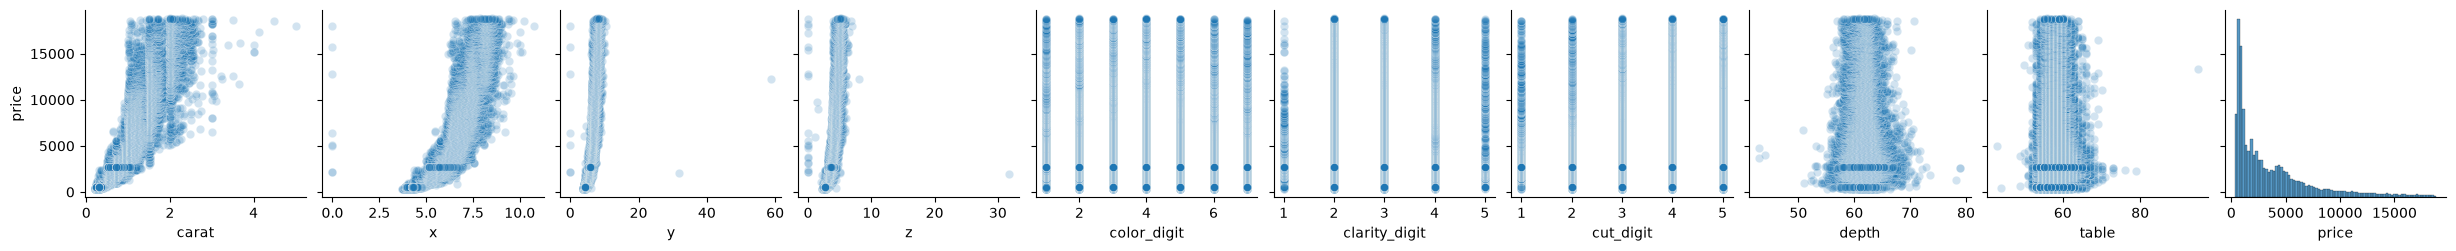

In [37]:
# График признаков попарно
plt.figure(figsize=(7,7))
%config InlineBackend.figure_format = 'png' # формат изображений PNG, для сокращения времени отрисовки графиков

sns.pairplot(
    df_digPlus[features + target],
    #hue = 'ColumnName',          # Признак разделения точек на подгруппы
    kind="scatter",         # Тип даграмм: reg,scatter
    diag_kind = 'hist',     # Тип диагоральных даграмм: hist, kde
    plot_kws={'alpha':0.2},  # прозрачность точек
    y_vars=target # График пар только для выбранного признака

);

## Поиск и обработка выбросов

Используем график диаграммы размаха (ящик с усами, box-plot) для оценки наличия нетипичных наблюдений (выбросов, outliers) - значений, которые в наборе данных сильно удалены от медианного значения.

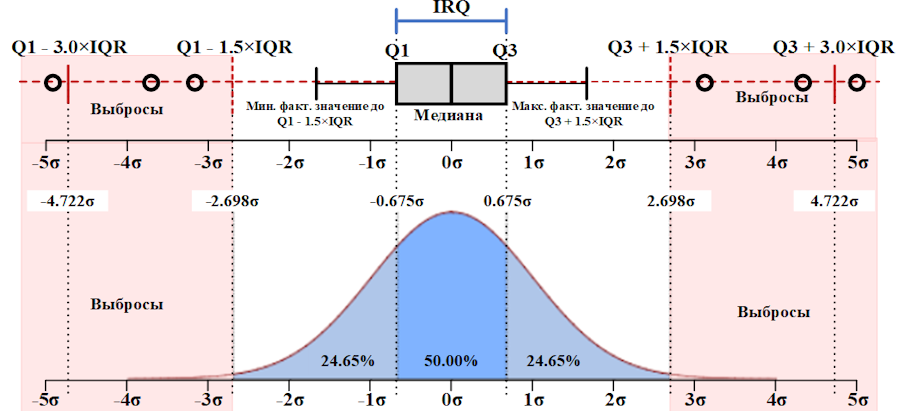

Судя по построенным диаграммам размаха (boxplot) нетипичные значения присуствуют. Для их фильтрации выберем граничные значения соответсвующие тонким краям ("усам").

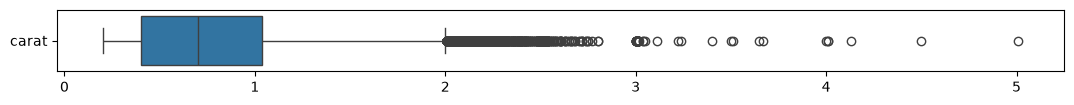

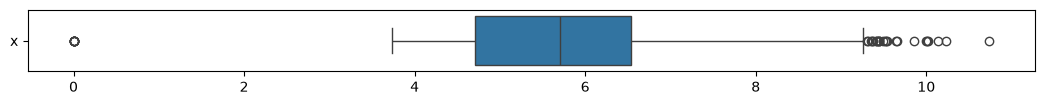

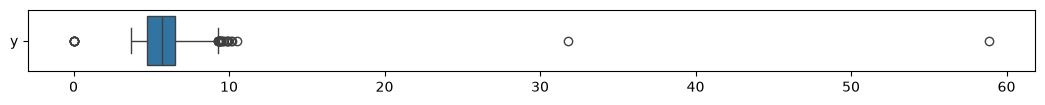

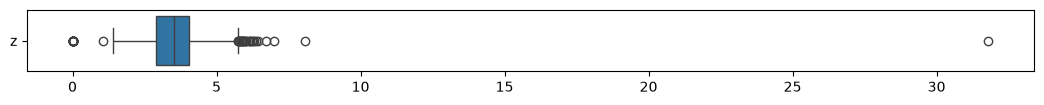

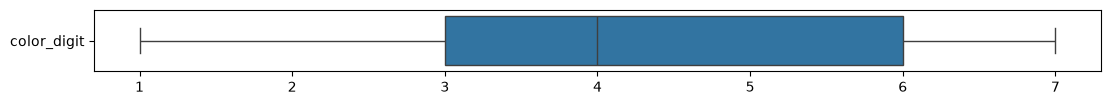

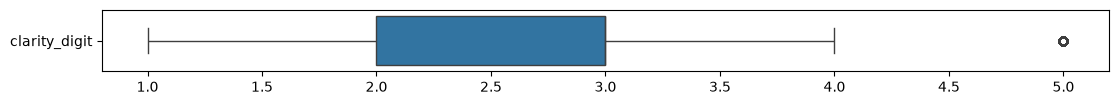

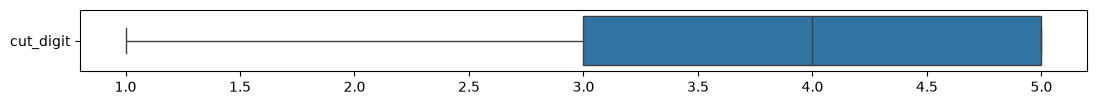

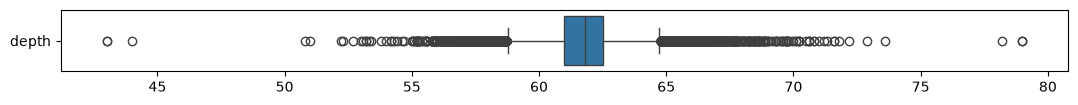

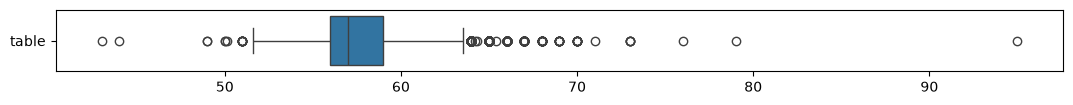

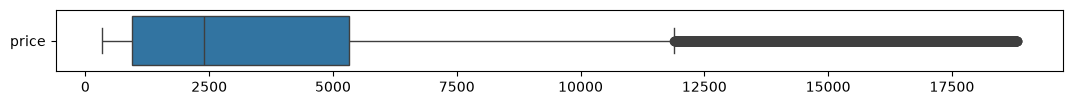

In [38]:
# Цикл: для каждого элемента в объединенном списке
for feature_name in (features+target):
    plt.figure(figsize=(13, 0.8)) # Построить полотно для рисования с указанным размером
    # На созданном полотне отрисовать boxplot
    sns.boxplot( data=df_digPlus[[feature_name]], # данные
                 orient='h' # ориентация графика
    )

Установим границы значений, для тех объектов таблицы, которые должны остаться

In [39]:
# создадим "словарь"/"хэш-таблицу" для удобного обращения, где ключ - это название признака
tressholdDict = {
    'carat'     : (0.2, 2)            , 
    'x' : (3.6, 9.2)     , 
    'y'  : (3, 9.5)        , 
    'z'     : (1, 6.5) ,
    'price' : (300, 12000),
    'depth' : (58, 65),
    'table' : (51, 64),
}

print (tressholdDict)

{'carat': (0.2, 2), 'x': (3.6, 9.2), 'y': (3, 9.5), 'z': (1, 6.5), 'price': (300, 12000), 'depth': (58, 65), 'table': (51, 64)}


Ранговые признаки (color, clarity, cut) не фильтровались, т.к. все их значения являются допустимыми градациями шкалы качества; точки за пределами "усов" соответствуют редким, но реальным категориям, а метод IQR предназначен для непрерывных величин

Отфильтруем значения которые находятся вне пороговых.

In [40]:
# Во избежание путаницы создадим для полседующих операций копию исходного объетка
df_digPlusFiltred = df_digPlus.copy()
for feature_name  in tressholdDict:
    threesMin =  tressholdDict[feature_name][0]
    tresshMax =  tressholdDict[feature_name][1]
    # фильтр по двум границам. Оператор "~" -инверсия логических значений
    df_digPlusFiltred = df_digPlusFiltred[
        (df_digPlusFiltred[feature_name] >= threesMin ) & (df_digPlusFiltred[feature_name] <= tresshMax)
    ]
    print("Обработан ", feature_name )
print ("Отброшено {} строк. Осталось {} строк.".format(    len(df_digPlus)  - len(df_digPlusFiltred), len(df_digPlusFiltred)))

Обработан  carat
Обработан  x
Обработан  y
Обработан  z
Обработан  price
Обработан  depth
Обработан  table
Отброшено 5181 строк. Осталось 48530 строк.


carat 0.2 2.0
x 3.73 8.3
y 3.68 8.27
z 1.07 5.3
color_digit 1 7
clarity_digit 1 5
cut_digit 1 5
depth 58.0 65.0
table 51.0 64.0
price 326.0 12000.0


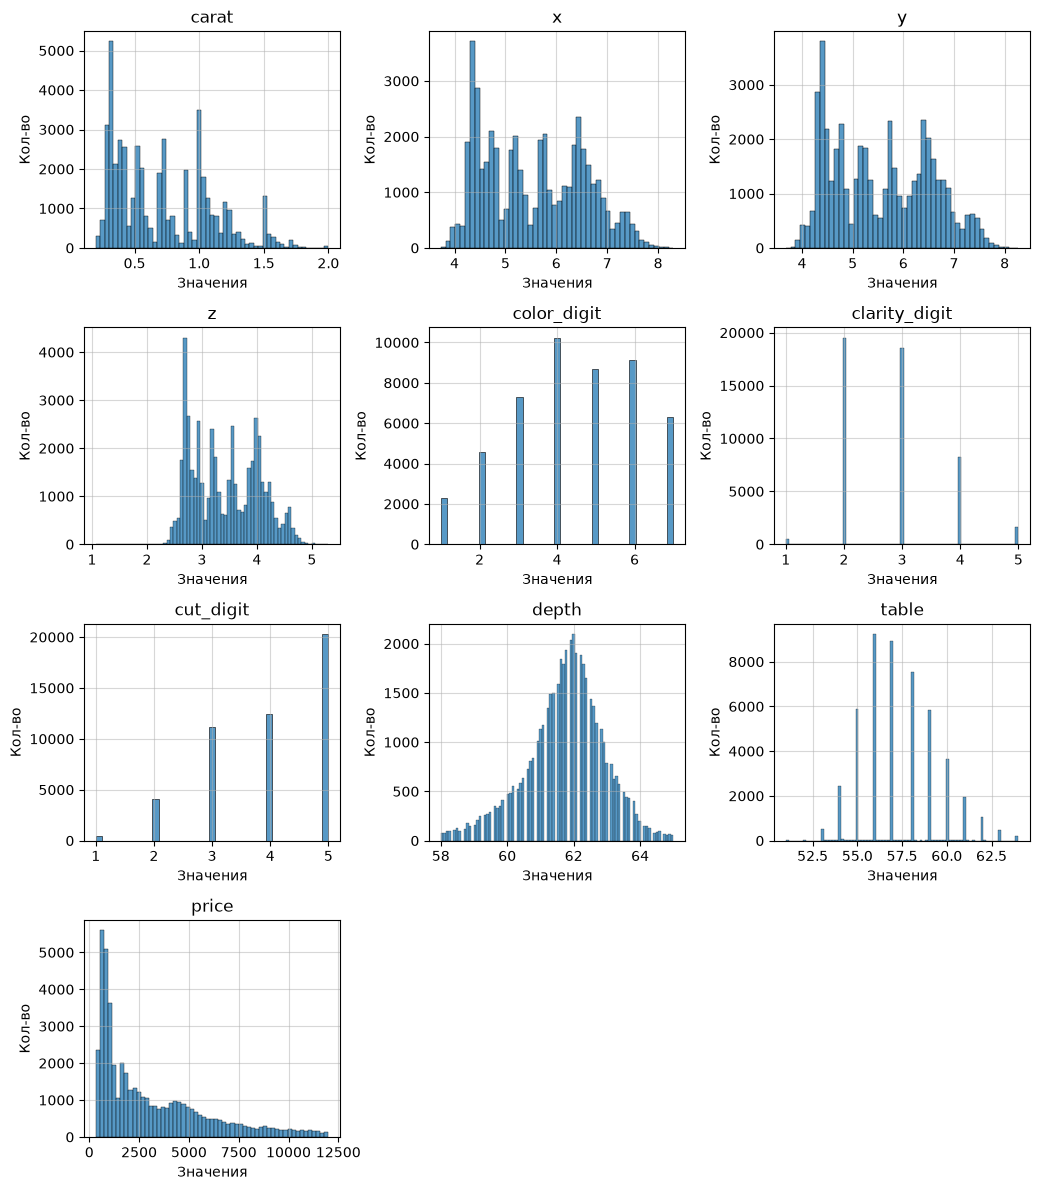

In [41]:
n_plots = len(features+target) # Кол-во графиков
n_cols = 3 # Кол-во столбцов
n_rows = n_plots//n_cols + (n_plots % n_cols > 0) # Кол-во строк
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*3.5, n_rows*3)) # Создаем полотно figure и axes
if n_rows == 1 and n_cols == 1:  axes = np.array([[axes]]) # Если axes не массив, преобразуем
elif n_rows == 1: axes = axes.reshape(1, -1)
elif n_cols == 1: axes = axes.reshape(-1, 1)

# Строим гистограммы по каждому признаку
for i, feature_name in enumerate(features+target):
    row, col= i // n_cols , i % n_cols # Номер строки, столбца графика
    ax = axes[row, col]
    sns.histplot(data=df_digPlusFiltred[feature_name],ax=ax) # Построение гистрограммы
    ax.set_title(feature_name) # Заголовок
    ax.grid(True, alpha=0.5) # Сетка
    ax.set_xlabel(u'Значения')
    ax.set_ylabel(u'Кол-во')
    print (feature_name,
           df_digPlusFiltred[feature_name].min(),
           df_digPlusFiltred[feature_name].max())
# Скрываем пустые subplot'ы
for i in range(n_plots, n_rows * n_cols):
    row, col= i // n_cols , i % n_cols # Номер строки, столбца графика
    axes[row, col].set_visible(False)

plt.tight_layout()

После исключения выбросов распределения признаков стали компактными, без «хвостов» ошибочных значений. Распределение массы (carat) многомодальное с выраженными пиками на «круглых» значениях (0.3, 0.5, 0.7, 1.0, 1.5, 2.0 карата), что объясняется рыночной практикой: камни огранивают так, чтобы масса достигала круглого значения, повышающего цену. Аналогичные пики наблюдаются у линейных размеров x, y, z, что подтверждает их сильную связь с массой. Среди ранговых признаков преобладают камни цвета G, чистоты SI–VS и огранки Ideal. Распределение цены имеет выраженную правостороннюю асимметрию: основная масса камней дешевле $2 500.

## Сохранение данных

In [42]:
df_digPlusFiltred.to_csv(
            'data/diamonds_nan_24_PREPARED.csv', # путь для сохранения
            index=False, # запрет сохранения "индексов" (тек. номеров строк)
           );

## Формирование тренировочной и проверочной выборок

Для разделения данных на тренировочную и проверочную выборки воспользуемся функцией `train_test_split` из пакета sklearn.

In [43]:
valid_size = 0.3 # доля тестовой части в выборке
rand_seed = 8 # начальное состояние генератора случ. чисел

x_train, x_test, y_train, y_test =  train_test_split(
    df_digPlusFiltred[features],    # исходные данные X
    df_digPlusFiltred[target],      # исходные данные y

    test_size = valid_size, # доля тестовой части в выборке
    random_state=rand_seed, # начальное состояние генератора случ. чисел
    shuffle=True            # перемешивание
)

In [44]:
print ("Кол-во элементов: \n  x_train: {}, y_train {} \n  x_test:  {}, y_test  {} \n  total x: {}, total y {} ".format  (
    len(x_train), len(y_train),
    len(x_test),  len(y_test),
    len(x_train)+len(x_test), len(y_train)+len(y_test),
))

Кол-во элементов: 
  x_train: 33971, y_train 33971 
  x_test:  14559, y_test  14559 
  total x: 48530, total y 48530 


Проверим содержимое обучающей и проверочной частей

In [45]:
x_test[:3]

,carat,x,y,z,color_digit,clarity_digit,cut_digit,depth,table
16165,1.03,6.61,6.68,3.98,7,2,5,59.9,57.0
45125,0.59,5.31,5.34,3.35,6,2,3,62.9,58.0
31947,0.30,4.32,4.28,2.65,5,3,5,61.6,57.0


In [46]:
y_test[:3]

,price
16165,6460.0
45125,1652.0
31947,776.0


# Построение модели

## Модель M1. Одномерная - от ЕДИНСТВЕННОГО признака 'carat'

Для получения линейной регрессионной модели созданим экземпляр класса
__sklearn.linear_model.LinearRegression()__

In [47]:
model_carat = linear_model.LinearRegression()

Полученная модель требует процедуры обучения - подбора значений коэфф. для минимизации отличий между вычисленными значениями и предоставленными целевыми (обучающими y).

In [48]:
# Вычислить коэфф. Ki в функции y(x)=Ki*xi + .... + B
# на тренировочном наборе, т.е. обучить модель
model_carat.fit(
    x_train[ ['carat', ] ], # x_train[['x1', 'x2', 'x3', ...]]
    y_train[ ['price'] ]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[6842.55]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['carat']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-1743.65]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Важным этапом является получение ответов от обученной модели, вычисленных на той части данных, которая не участвовала в обучении (т.е не участвовала в подстройке коэфф. мат. модели)

In [49]:
# Получить вычисленные(predicted) зн. на проверочном наборе
# y_pred = fittedModel.predict(x_test)
y_predicted_on_carat = model_carat.predict(x_test[ ['carat', ] ]) # x_train[['x1', 'x2', 'x3', ...]]

Для наглядности построим график рассеяния (он же график разброса, точечный, scatter) зависимой величины y от **единственного** определяющего признака

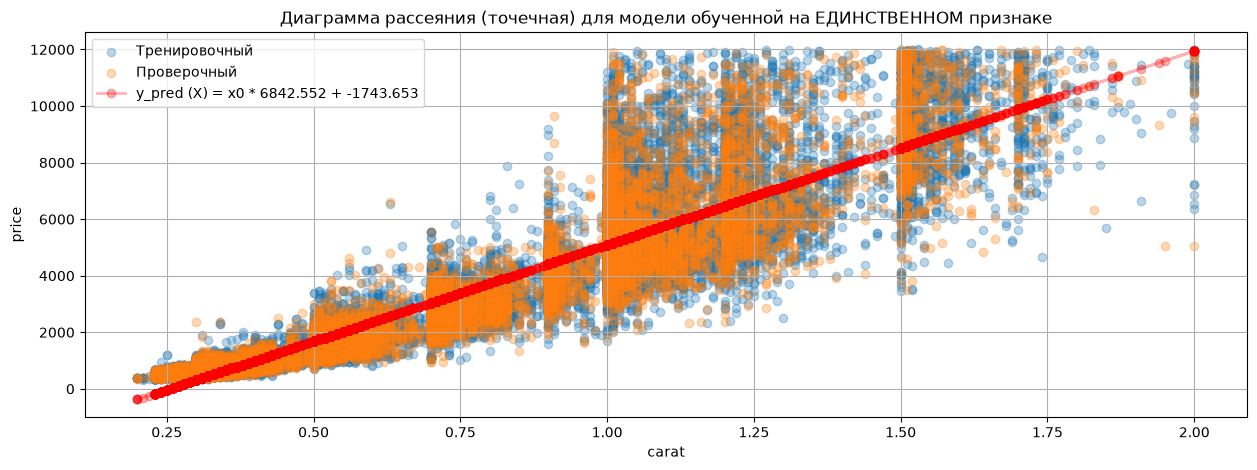

In [50]:
# Создать полотно для рисования с указаными размерами
plt.figure(figsize=(15,5))

# Точечная диаграмма (диаграмма рассеяния) - plt.scatter
plt.scatter(x_train[['carat']],  y_train[['price']], alpha=0.3, label='Тренировочный') # тренировочный
plt.scatter(x_test[['carat']],   y_test[['price']],  alpha=0.3, label='Проверочный')   # проверочный

# Нанести график - линии, проведённые через точки - plt.plot
plt.plot( x_test[['carat']], y_predicted_on_carat,
          lw=2, color='red', alpha=0.3, marker='o',
          label="y_pred (X) = x0 * {:.3f} + {:.3f}".format(model_carat.coef_[0][0], model_carat.intercept_[0]))
plt.grid(True)  # Сетка. Доп параметры color='black', linewidth=0.7
plt.legend(loc="best")  # Положение легенды
plt.xlabel('carat') # Подпись осей
plt.ylabel(target[0])   # Подпись осей
plt.title(u'Диаграмма рассеяния (точечная) для модели обученной на ЕДИНСТВЕННОМ признаке'); # Заголовок

Модель M1: price = 6842.6 · carat − 1743.7. Увеличение массы на 1 карат в среднем повышает цену на ≈ 6 840. На диаграмме рассеяния видно, что зависимость цены от массы нелинейна: для мелких камней модель занижает цену. Кроме того, при одинаковой массе (например, 1.0 и 1.5 карата) цена варьируется в широких пределах (2 000–12 000), что указывает на влияние других признаков.

Т.к. модель является линейной имеются некоторые расхождения между реальными и вычисленными значениями - "ошибки". Для оценки точности построим гистограмму распределения ошибок

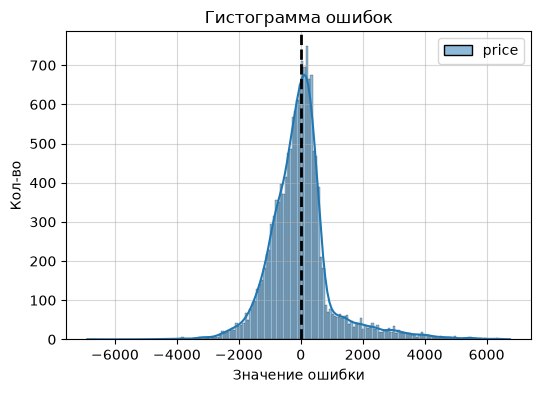

In [51]:
plt.figure(figsize=(6,4))
# Гистограмма и Плотность распределения - sns.distplot
# data = y_true - y_pred
sns.histplot( data = y_test[['price']] - y_predicted_on_carat,
              color="red",
              kde=True, # оценка плотности в виде кривой
              #stat="density",# density: общая площадь равна 1
)
plt.axvline(x=0, color='black', linestyle= 'dashed', linewidth=2,)  # Осевая линия
plt.ylabel(u'Кол-во')
plt.xlabel(u'Значение ошибки')
plt.grid(True, alpha=0.5) # Сетка
plt.title(u'Гистограмма ошибок');

Ошибки модели M1 распределены вокруг нуля, систематического смещения нет; основная часть ошибок лежит в пределах ±1 000. 
Построим еще пару графиков для визуальной оценки качества модели:
- график рассеяния вычисленных значений Y_pred от проверочных значений Y_test;
- график квадратов ошибок от проверочных значний Y_test.

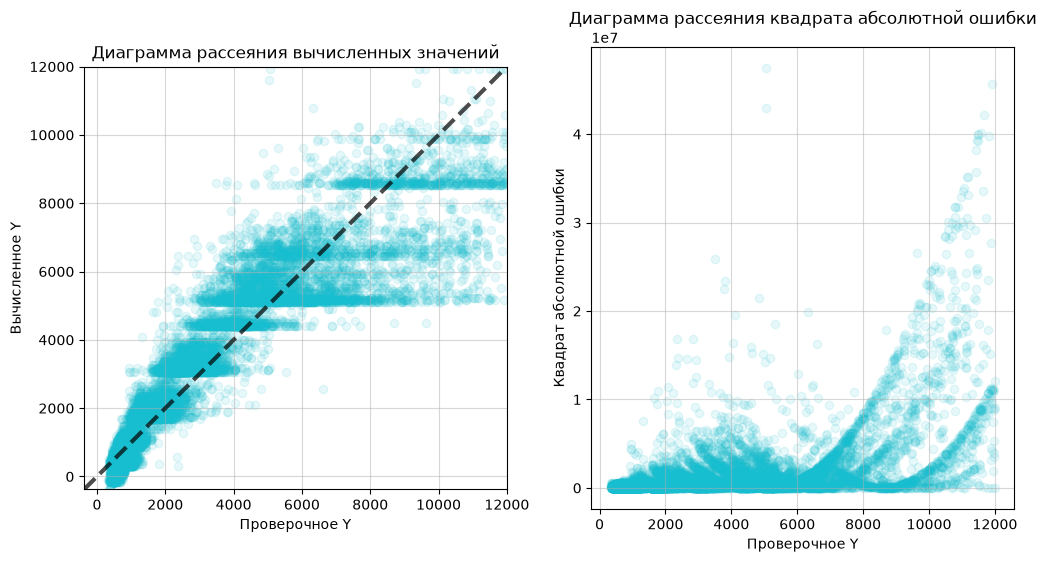

In [52]:
def PLOT34(y_test, y_pred) -> None:
    '''
    Функция построения графиков
    :param y_test: - проверочные значения целевой переменной
    :param y_pred: - вычисленные значения целевой переменной
    '''
    plt.figure(figsize=(12,6))

    # == Диаграмма рассеяния вычисленных значений ==
    # создать первое полотно 121: 1-строк, 2-столбцов, 1-индекс текущего полотна в сетке
    plt.subplot(121)
    plt.scatter(y_test, y_pred,  alpha=0.1, color = "#17becf")
    plt.axline((0, 0), slope=1, color='black', linestyle='--', linewidth=3, alpha=0.7,)
    range_test, range_pred = np.max(y_test)- np.min(y_test) , np.max(y_pred)- np.min(y_pred)
    if range_test/range_pred <4 and range_test/range_pred > 0.25:
        plt.gca().set_aspect('equal')
        axmin, axmax = np.min([y_test, y_pred]), np.max([y_test, y_pred])
        plt.xlim([axmin, axmax]); plt.ylim([axmin, axmax]);
    plt.title('Диаграмма рассеяния вычисленных значений');
    plt.xlabel('Проверочное Y');    plt.ylabel('Вычисленное Y');
    plt.grid(True,  alpha=0.5)   # Сетка

    # == Диаграмма рассеяния ошибок ==
    # создать второе полотно 121: 1-строк, 2-столбцов, 2-индекс текущего полотна в сетке
    plt.subplot(122)
    plt.scatter(y_test, (y_test - y_pred)**2,  alpha=0.1, color = "#17becf")
    plt.title('Диаграмма рассеяния квадрата абсолютной ошибки')
    plt.xlabel('Проверочное Y');    plt.ylabel('Квадрат абсолютной ошибки');
    plt.grid(True,  alpha=0.5)  # Сетка
#--------------------------------------------------------------------------

PLOT34(
    y_test = y_test[['price']],
    y_pred = y_predicted_on_carat
)

На диаграмме рассеяния вычисленных значений точки образуют горизонтальные полосы: модель M1 учитывает только массу, поэтому камни одинаковой массы (например, 1.0 и 1.5 карата) получают одинаковый прогноз, хотя их реальная цена различается на тысячи долларов. Облако точек изогнуто относительно диагонали: модель занижает цену дешёвых и дорогих камней и завышает цену камней среднего ценового диапазона, что подтверждает нелинейный характер зависимости. Диаграмма квадратов ошибки показывает резкий рост ошибки для камней дороже $8 000 (гетероскедастичность): чем дороже камень, тем сильнее его цена определяется не только массой, но и качеством (цвет, чистота, огранка).

С помощью функций __sklearn.metrics.*__ сравним реальные и вычисленные значениямя и получим важные оценки качества модели

In [53]:
print ("Линейная одномерная регрессия. Признак 'carat'.")
print ("Формула линейной регресси y(X) = k0*x0 + ... kN*xN + b")
print(f"y = f(X) = ")
for i, kN in enumerate (model_carat.coef_[0]):
    print(f" {' ' if i==0 else '+'}  {kN:12.3f} * x{i} ")
print(f"+ {model_carat.intercept_[0]:.3f} ")
print("\n")

Линейная одномерная регрессия. Признак 'carat'.
Формула линейной регресси y(X) = k0*x0 + ... kN*xN + b
y = f(X) = 
        6842.552 * x0 
+ -1743.653 




In [54]:
'''
Вычисление и вывод метрик: MAE, RMSE, R2. На основе сравнения проверочных и вычисленных значений.
'''
mae  = metrics.mean_absolute_error(y_test, y_predicted_on_carat)
mse  = metrics.mean_squared_error (y_test, y_predicted_on_carat)
rmse = np.sqrt(mse)
r2   = metrics.r2_score           (y_test, y_predicted_on_carat)
print ("MAE : {:>9,.3f} (средняя абсолютная ошибка)".format( mae ))
print ("MSE : {:>9,.6f} (среднеквадратичная ошибка)".format( mse ))
print ("RMSE: {:>9,.6f} (кв. корень из среднеквадратичной ошибки)".format( rmse ))
print ("R2  : {:>9,.3f} (коэфф. детерминации)".format      ( r2 ))

MAE :   707.954 (средняя абсолютная ошибка)
MSE : 1,146,743.683705 (среднеквадратичная ошибка)
RMSE: 1,070.861188 (кв. корень из среднеквадратичной ошибки)
R2  :     0.849 (коэфф. детерминации)


## Модель М2. Многомерная - от НАБОРА_признаков_№2 - carat, color_digit, clarity_digit

In [55]:
model_m2 = linear_model.LinearRegression()

model_m2.fit(
    x_train[ ['carat', 'color_digit', 'clarity_digit'] ], 
    y_train[ ['price'] ]
)

y_predicted_on_m2 = model_m2.predict(x_test[ ['carat', 'color_digit', 'clarity_digit'] ])

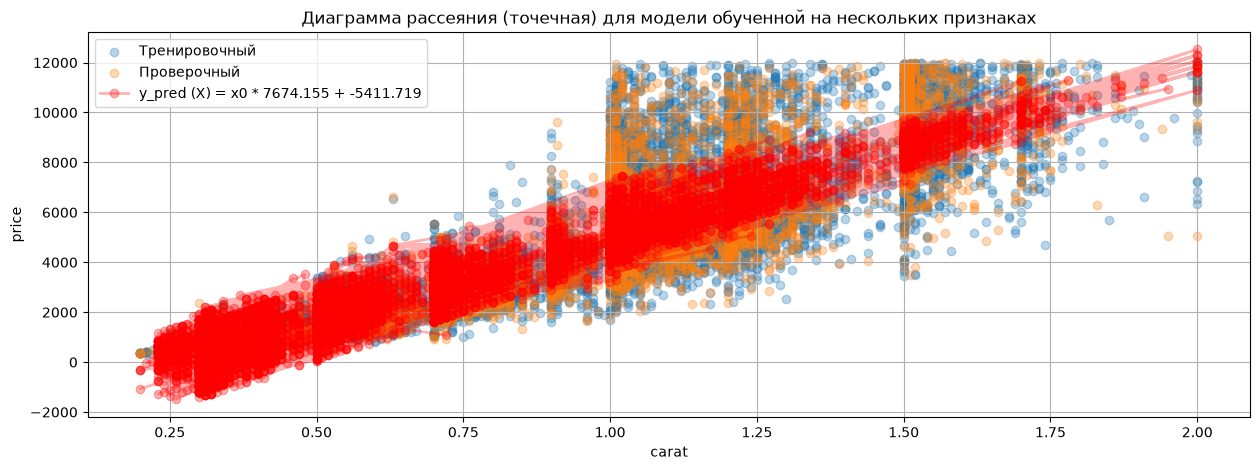

In [56]:
# Создать полотно для рисования с указаными размерами
plt.figure(figsize=(15,5))

# Точечная диаграмма (диаграмма рассеяния) - plt.scatter
plt.scatter(x_train[['carat']],  y_train[['price']], alpha=0.3, label='Тренировочный') # тренировочный
plt.scatter(x_test[['carat']],   y_test[['price']],  alpha=0.3, label='Проверочный')   # проверочный

# Нанести график - линии, проведённые через точки - plt.plot
plt.plot( x_test[['carat']], y_predicted_on_m2,
          lw=2, color='red', alpha=0.3, marker='o',
          label="y_pred (X) = x0 * {:.3f} + {:.3f}".format(model_m2.coef_[0][0], model_m2.intercept_[0]))
plt.grid(True)  # Сетка. Доп параметры color='black', linewidth=0.7
plt.legend(loc="best")  # Положение легенды
plt.xlabel('carat') # Подпись осей
plt.ylabel(target[0])   # Подпись осей
plt.title(u'Диаграмма рассеяния (точечная) для модели обученной на нескольких признаках'); # Заголовок

Сравнение с M1. В M1 все прогнозы лежали на одной прямой, и камни одинаковой массы получали одинаковую цену. В M2 прогноз «расщепился» по качеству и лучше накрывает реальный разброс цен.

Учёт цвета и чистоты позволяет модели различать камни одной массы. Но форма зависимости осталась линейной, поэтому у мелких камней модель уходит в отрицательные цены, а у крупных недооценивает верхнюю часть облака.

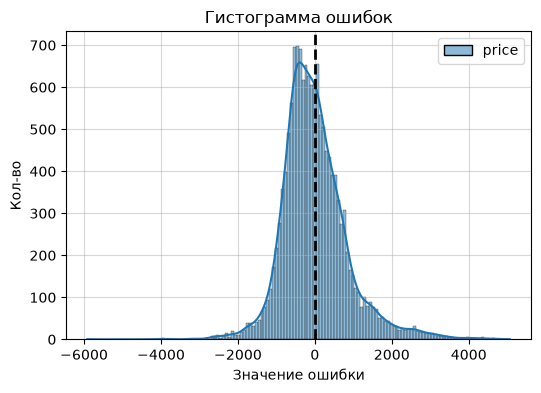

In [57]:
plt.figure(figsize=(6,4))
# Гистограмма и Плотность распределения - sns.distplot
# data = y_true - y_pred
sns.histplot( data = y_test[['price']] - y_predicted_on_m2,
              color="red",
              kde=True, # оценка плотности в виде кривой
              #stat="density",# density: общая площадь равна 1
)
plt.axvline(x=0, color='black', linestyle= 'dashed', linewidth=2,)  # Осевая линия
plt.ylabel(u'Кол-во')
plt.xlabel(u'Значение ошибки')
plt.grid(True, alpha=0.5) # Сетка
plt.title(u'Гистограмма ошибок');

Ошибки M2 стали меньше и симметричнее. Сильные занижения цены дорогих камней встречаются реже, потому что часть их «дороговизны» теперь объясняется цветом и чистотой.

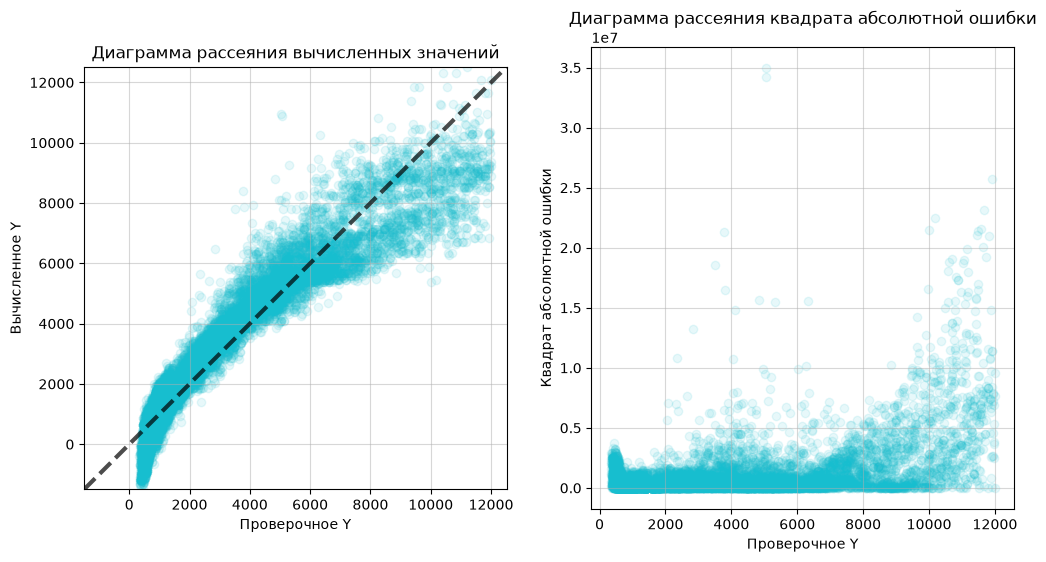

In [58]:
PLOT34(
    y_test = y_test[['price']],
    y_pred = y_predicted_on_m2
)

M2 точнее M1 по всему диапазону цен, но ошибается на краях: занижает цену дешёвых и дорогих камней, слегка завышает средние.

In [59]:
print ("Линейная многомерная регрессия.")
print ("Формула линейной регрессия y(X) = k0*x0 + ... kN*xN + b")
print(f"y = f(X) = ")
for i, kN in enumerate (model_m2.coef_[0]):
    print(f" {' ' if i==0 else '+'}  {kN:12.3f} * x{i} ")
print(f"+ {model_m2.intercept_[0]:.3f} ")
print("\n")

Линейная многомерная регрессия.
Формула линейной регрессия y(X) = k0*x0 + ... kN*xN + b
y = f(X) = 
        7674.155 * x0 
 +       222.574 * x1 
 +       738.193 * x2 
+ -5411.719 




In [60]:
'''
Вычисление и вывод метрик: MAE, RMSE, R2. На основе сравнения проверочных и вычисленных значений.
'''
mae  = metrics.mean_absolute_error(y_test, y_predicted_on_m2)
mse  = metrics.mean_squared_error (y_test, y_predicted_on_m2)
rmse = np.sqrt(mse)
r2   = metrics.r2_score           (y_test, y_predicted_on_m2)
print ("MAE : {:>9,.3f} (средняя абсолютная ошибка)".format( mae ))
print ("MSE : {:>9,.6f} (среднеквадратичная ошибка)".format( mse ))
print ("RMSE: {:>9,.6f} (кв. корень из среднеквадратичной ошибки)".format( rmse ))
print ("R2  : {:>9,.3f} (коэфф. детерминации)".format      ( r2 ))

MAE :   623.357 (средняя абсолютная ошибка)
MSE : 736,003.833108 (среднеквадратичная ошибка)
RMSE: 857.906658 (кв. корень из среднеквадратичной ошибки)
R2  :     0.903 (коэфф. детерминации)


Добавление признаков цвета и чистоты повысило R² с 0.849 до 0.903. Коэффициенты при color_digit и clarity_digit положительны, хотя коэффициенты корреляции этих признаков с ценой отрицательны. Это объясняется тем, что камни высокого качества в среднем имеют меньшую массу. Коэффициент при массе вырос до 7 674, т.к. модель отделила влияние массы от влияния качества.

## Модель М3. Многомерная - от НАБОРА_признаков_№3 - carat, color_digit, clarity_digit, cut_digit

In [61]:
model_m3 = linear_model.LinearRegression()

model_m3.fit(
    x_train[ ['carat', 'color_digit', 'clarity_digit', 'cut_digit'] ], 
    y_train[ ['price'] ]
)

y_predicted_on_m3 = model_m3.predict(x_test[ ['carat', 'color_digit', 'clarity_digit', 'cut_digit'] ])

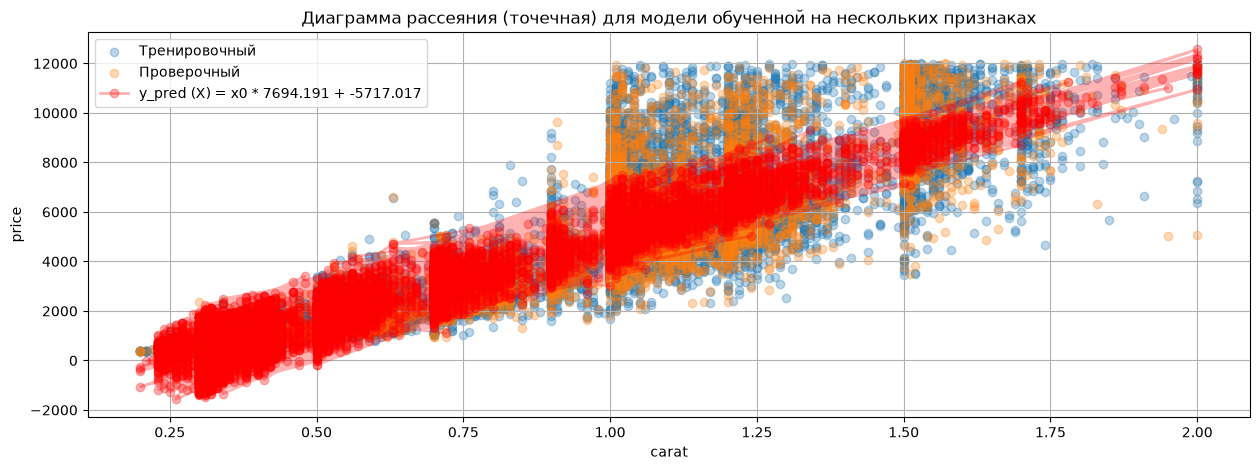

In [62]:
plt.figure(figsize=(15,5))

# Точечная диаграмма (диаграмма рассеяния) - plt.scatter
plt.scatter(x_train[['carat']],  y_train[['price']], alpha=0.3, label='Тренировочный') # тренировочный
plt.scatter(x_test[['carat']],   y_test[['price']],  alpha=0.3, label='Проверочный')   # проверочный

# Нанести график - линии, проведённые через точки - plt.plot
plt.plot( x_test[['carat']], y_predicted_on_m3,
          lw=2, color='red', alpha=0.3, marker='o',
          label="y_pred (X) = x0 * {:.3f} + {:.3f}".format(model_m3.coef_[0][0], model_m3.intercept_[0]))
plt.grid(True)  # Сетка. Доп параметры color='black', linewidth=0.7
plt.legend(loc="best")  # Положение легенды
plt.xlabel('carat') # Подпись осей
plt.ylabel(target[0])   # Подпись осей
plt.title(u'Диаграмма рассеяния (точечная) для модели обученной на нескольких признаках'); # Заголовок

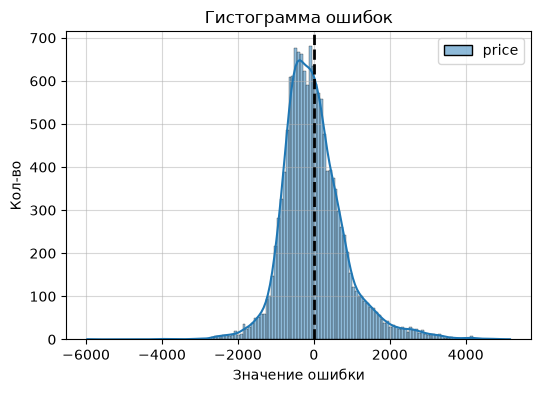

In [63]:
plt.figure(figsize=(6,4))
# Гистограмма и Плотность распределения - sns.distplot
# data = y_true - y_pred
sns.histplot( data = y_test[['price']] - y_predicted_on_m3,
              color="red",
              kde=True, # оценка плотности в виде кривой
              #stat="density",# density: общая площадь равна 1
)
plt.axvline(x=0, color='black', linestyle= 'dashed', linewidth=2,)  # Осевая линия
plt.ylabel(u'Кол-во')
plt.xlabel(u'Значение ошибки')
plt.grid(True, alpha=0.5) # Сетка
plt.title(u'Гистограмма ошибок');

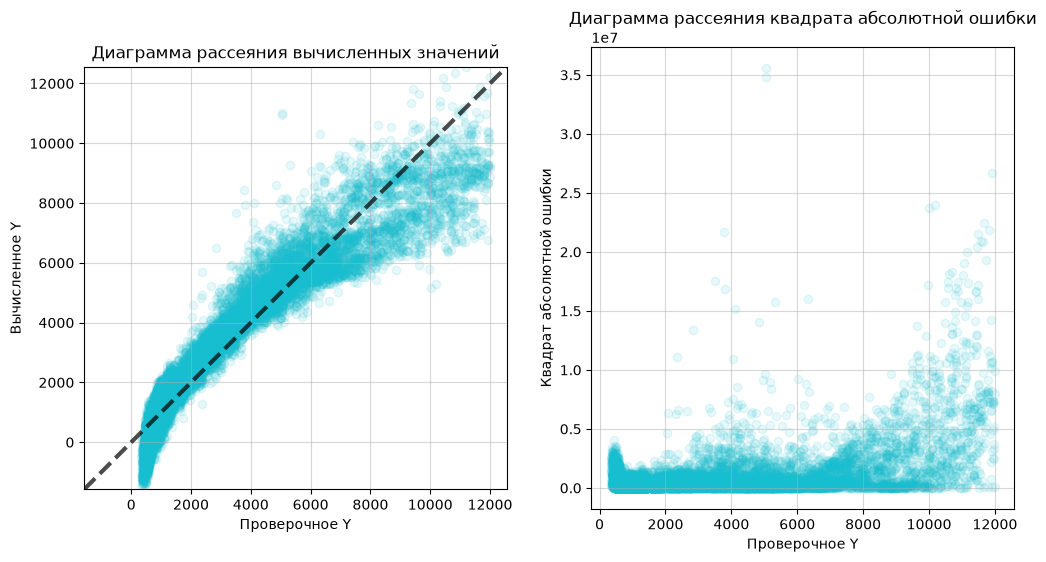

In [64]:
PLOT34(
    y_test = y_test[['price']],
    y_pred = y_predicted_on_m3
)

In [65]:
print ("Линейная многомерная регрессия.")
print ("Формула линейной регресси y(X) = k0*x0 + ... kN*xN + b")
print(f"y = f(X) = ")
for i, kN in enumerate (model_m3.coef_[0]):
    print(f" {' ' if i==0 else '+'}  {kN:12.3f} * x{i} ")
print(f"+ {model_m3.intercept_[0]:.3f} ")
print("\n")

Линейная многомерная регрессия.
Формула линейной регресси y(X) = k0*x0 + ... kN*xN + b
y = f(X) = 
        7694.191 * x0 
 +       222.679 * x1 
 +       723.529 * x2 
 +        83.124 * x3 
+ -5717.017 




In [66]:
'''
Вычисление и вывод метрик: MAE, RMSE, R2. На основе сравнения проверочных и вычисленных значений.
'''
mae  = metrics.mean_absolute_error(y_test, y_predicted_on_m3)
mse  = metrics.mean_squared_error (y_test, y_predicted_on_m3)
rmse = np.sqrt(mse)
r2   = metrics.r2_score           (y_test, y_predicted_on_m3)
print ("MAE : {:>9,.3f} (средняя абсолютная ошибка)".format( mae ))
print ("MSE : {:>9,.6f} (среднеквадратичная ошибка)".format( mse ))
print ("RMSE: {:>9,.6f} (кв. корень из среднеквадратичной ошибки)".format( rmse ))
print ("R2  : {:>9,.3f} (коэфф. детерминации)".format      ( r2 ))

MAE :   619.726 (средняя абсолютная ошибка)
MSE : 728,976.314444 (среднеквадратичная ошибка)
RMSE: 853.801098 (кв. корень из среднеквадратичной ошибки)
R2  :     0.904 (коэфф. детерминации)


Коэффициент при cut_digit положителен, хотя корреляция с ценой отрицательна. Добавление огранки повысило R² лишь с 0.903 до 0.904. Графики M3 практически совпадают с графиками M2, огранка вносит малый вклад в цену при учёте массы, цвета и чистоты.

# Итоги. Сравнение полученных моделей

Основные численные значения, полученные в работе:
- Размеры таблиц данных на этапах:
  - исходная таблица при загрузке csv-файла : 53940 Строк x 11 Столбцов
  - после исключения пропущенных значений : 53711 Строк x 10 Столбцов
  - после исключения выбросов : 48530 Строк x 10 Столбцов

Численные оценки всех моделей для более удобного сравнения:

      M1. Линейная одномерная регрессия. Признаки: 'carat'.
        Формула линейной регресси y(x) = 6842.509 * x0 - 1743.653
        MAE : 707.954 (средняя абсолютная ошибка)
        MSE : 1 146 743.684 (среднеквадратичная ошибка)
        RMSE: 1 070.861 (кв. корень из среднеквадратичной ошибки)
        R2  : 0.849 (коэфф. детерминации)

      M2. Линейная многомерная регрессия. Признаки: 'carat', 'color_digit', 'clarity_digit'.
        Формула линейной регресси y(x) = 7674.155 * x0 + 222.574 * x1 + 738.193 * x2 - 5411.719
        MAE : 623.357 (средняя абсолютная ошибка)
        MSE : 736 003.833 (среднеквадратичная ошибка)
        RMSE: 857.907 (кв. корень из среднеквадратичной ошибки)
        R2  : 0.903 (коэфф. детерминации)
      
      M3 Линейная многомерная регрессия. Признаки: 'carat', 'color_digit', 'clarity_digit', 'cut_digit'.
        Формула линейной регресси y(x) = 7694.191 * x0 + 222.679 * x1 + 723.529 * x2 + 83.124 * x3 - 5717.017 
        MAE : 619.726 (средняя абсолютная ошибка)
        MSE : 728 976.314 (среднеквадратичная ошибка)
        RMSE: 853.801 (кв. корень из среднеквадратичной ошибки)
        R2  : 0.904 (коэфф. детерминации)

Время затраченное на выполнение основных этапов работы согласно методологии CRISP:

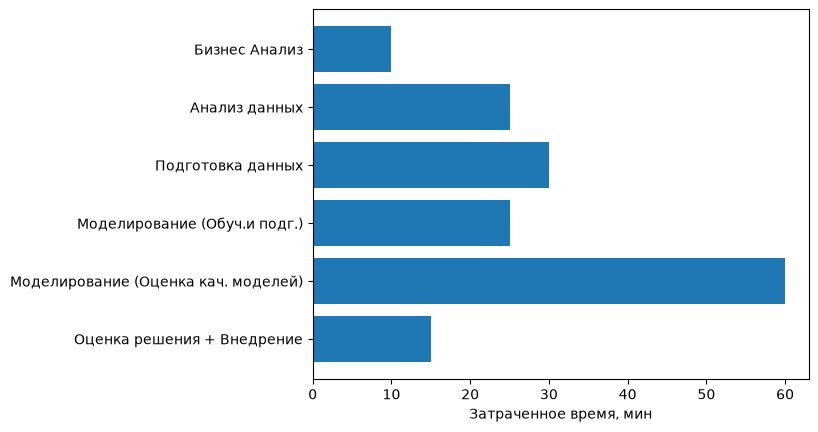

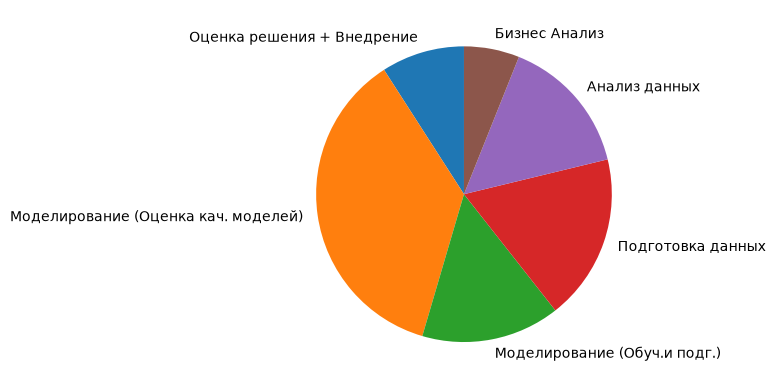

In [67]:
# Создадим датафрейм для хранения значений
dfSpendTimeLab1 = pd.DataFrame.from_dict(
{
  "1": {"step": "Бизнес Анализ",                       "duration, min" :  10  },
  "2": {"step": "Анализ данных",                       "duration, min" :  25  },
  "3": {"step": "Подготовка данных",                   "duration, min" :  30  },
  "4": {"step": "Моделирование (Обуч.и подг.)",        "duration, min" :  25  },
  "5": {"step": "Моделирование (Оценка кач. моделей)", "duration, min" :  60  },
  "6": {"step": "Оценка решения + Внедрение",          "duration, min" :  15  },
}
, orient="index"
).sort_index(ascending=False)

# Построить столбчатую диаграмму
fig = plt.figure()
plt.barh(y = dfSpendTimeLab1["step"], width= dfSpendTimeLab1["duration, min"], )
plt.xlabel("Затраченное время, мин")

# Построить круговую диаграмму
fig = plt.figure()
plt.pie(x= dfSpendTimeLab1["duration, min"], labels=dfSpendTimeLab1["step"],  startangle = 90 )

plt.show()

# Выводы по работе

Максимальное значение R² = 0.904 у модели M3 (признаки: carat, color_digit, clarity_digit, cut_digit). Она объясняет 90.4% дисперсии цены.

По значению R² модели различаются незначительно: M2 превосходит M1 в 0.903 / 0.849 ≈ 1.06 раза, M3 превосходит M1 в 0.904 / 0.849 ≈ 1.06 раза, а M3 превосходит M2 лишь в 0.904 / 0.903 ≈ 1.001 раза. Небольшая разница объясняется тем, что уже одномерная модель M1 имеет высокое значение R².

carat - основной и обязательный признак, в одиночку обеспечивает R² = 0.849.
clarity_digit и color_digit - необходимые дополнительные признаки: вместе повышают R² на 0.054. Чистота влияет сильнее цвета.
cut_digit - малозначимый признак: повышает R² лишь на 0.001, без него точность модели практически не меняется.
R² растёт при каждом добавлении признака, но прирост быстро уменьшается.

Признаки качества по отдельности слабо и даже отрицательно коррелируют с ценой, но в сочетании с массой повышают точность. Дальнейшее добавление признаков даёт всё меньший эффект, ограничение точности связано не с набором признаков, а с нелинейной зависимостью цены от массы.